In [6]:
import math
import numpy as np
import pandas as pd
import upsetplot as upset
import seaborn as sns
sns.set_style("white")
sns.set_style("ticks")
import matplotlib.pyplot as plt
plt.show()
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib as mpl

In [7]:
# get lncRNA and mRNA list from BiomaRt
lncrna = pd.read_table('Fig4/biomart_ensembl_lncrna.txt')
lncrna_list = lncrna['Geneid'].tolist()
mrna = pd.read_table('Fig4/biomart_ensembl_mrna.txt')
mrna_list = mrna['Geneid'].tolist()

In [8]:
# get read counts table
read_counts = pd.read_table('Fig4/counts_strand_s2.out.txt')
gene_length = dict(zip(read_counts['Geneid'].tolist(), read_counts['Length'].tolist()))
read_counts = read_counts.drop(columns=['Chr', 'Start', 'End', 'Strand', 'Length']).set_index('Geneid', drop=True)
read_counts.head()

,shNT_cyto_1,shNT_cyto_2,shNT_noyau_1,shNT_noyau_2,shPABPN1_cyto_1,shPABPN1_cyto_2,shPABPN1_noyau_1,shPABPN1_noyau_2
Geneid,,,,,,,,
ENSG00000142611,0,2,0,2,6,0,2,0
ENSG00000284616,0,0,0,0,0,0,0,0
ENSG00000157911,6105,6661,2174,2580,3278,3879,2251,2644
ENSG00000260972,0,0,0,0,0,0,0,0
ENSG00000224340,0,0,0,2,0,0,0,0


In [9]:
# calculate TPM
# RPK calculation
rows_list = []
for gene in read_counts.index.tolist() :
    rows_list.append((read_counts.loc[[gene]] / gene_length[gene]) * 1000)
rpk = pd.concat(rows_list)

# TPM calculation
scaling_factors = {}
for sample in rpk.columns.tolist():
    scaling_factors[sample] = rpk[sample].sum() / 1000000

list_tpm = []
for sample in rpk.columns.tolist() :
    list_tpm.append(rpk[sample] / scaling_factors[sample]) # list of series

tpm = list_tpm[0].to_frame() # combine the series
for i in range (1, len(list_tpm)) :
    tpm = tpm.join(list_tpm[i])
tpm = tpm.reset_index()

tpm.head()

,Geneid,shNT_cyto_1,shNT_cyto_2,shNT_noyau_1,shNT_noyau_2,shPABPN1_cyto_1,shPABPN1_cyto_2,shPABPN1_noyau_1,shPABPN1_noyau_2
0,ENSG00000142611,0.000000,0.003722,0.000000,0.008910,0.014068,0.000000,0.008874,0.000000
1,ENSG00000284616,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,ENSG00000157911,32.625065,32.014276,28.126533,29.682345,19.848069,20.208363,25.793784,26.436219
3,ENSG00000260972,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,ENSG00000224340,0.000000,0.000000,0.000000,0.258226,0.000000,0.000000,0.000000,0.000000


In [10]:
# for cyto or nucleus gene expression comparison, keep genes with tpm > 1 in both replicates of at least one condition (shNT or shPABPN1)
tpm['expression_cyto'] = 'low'
tpm.loc[((tpm['shNT_cyto_1'] >= 1) & (tpm['shNT_cyto_2'] >= 1)) | ((tpm['shPABPN1_cyto_1'] >= 1) & (tpm['shPABPN1_cyto_2'] >= 1)), 'expression_cyto'] = 'high'
tpm['expression_nucleus'] = 'low'
tpm.loc[((tpm['shNT_noyau_1'] >= 1) & (tpm['shNT_noyau_2'] >= 1)) | ((tpm['shPABPN1_noyau_1'] >= 1) & (tpm['shPABPN1_noyau_2'] >= 1)), 'expression_nucleus'] = 'high'
tpm.to_csv('Fig4/tpm.txt', sep = '\t')


In [11]:
results_DESeq2_all = pd.read_table('Fig4/resDF_all.txt')
results_DESeq2_all = results_DESeq2_all[results_DESeq2_all['baseMean'] >= 10] # filter on basemean for sufficient coverage
results_DESeq2_all['localization_diff'] = 'No change'
results_DESeq2_all.loc[(results_DESeq2_all['padj'] < 0.05) & (results_DESeq2_all['log2FoldChange'] >= 1), 'localization_diff'] = 'More cytoplasmic'
results_DESeq2_all.loc[(results_DESeq2_all['padj'] < 0.05) & (results_DESeq2_all['log2FoldChange'] <= -(1)), 'localization_diff'] = 'More nuclear'
results_DESeq2_all_count = results_DESeq2_all.groupby(by = ['localization_diff', 'type'])['Geneid'].count().reset_index()
genes_more_nuclear = results_DESeq2_all[results_DESeq2_all['localization_diff'] == 'More nuclear']['Geneid'].drop_duplicates().tolist()
genes_more_cytoplasmic = results_DESeq2_all[results_DESeq2_all['localization_diff'] == 'More cytoplasmic']['Geneid'].drop_duplicates().tolist()
mrna_more_nuclear = results_DESeq2_all[(results_DESeq2_all['localization_diff'] == 'More nuclear') & (results_DESeq2_all['type'] == 'mRNA')]['Geneid'].drop_duplicates().tolist()
mrna_more_cytoplasmic = results_DESeq2_all[(results_DESeq2_all['localization_diff'] == 'More cytoplasmic') & ((results_DESeq2_all['type'] == 'mRNA'))]['Geneid'].drop_duplicates().tolist()
lncrna_more_nuclear = results_DESeq2_all[(results_DESeq2_all['localization_diff'] == 'More nuclear') & (results_DESeq2_all['type'] == 'lncRNA')]['Geneid'].drop_duplicates().tolist()
lncrna_more_cytoplasmic = results_DESeq2_all[(results_DESeq2_all['localization_diff'] == 'More cytoplasmic') & ((results_DESeq2_all['type'] == 'lncRNA'))]['Geneid'].drop_duplicates().tolist()

results_DESeq2_all.head()

,Geneid,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,gene_name,mRNA,lncrna,type,localization_diff
35867,ENSG00000242125,42794.566163,4.076360,0.176764,23.061052,1.139494e-117,2.436695e-113,SNHG3,NaN,True,lncRNA,More cytoplasmic
23540,ENSG00000218739,12637.674099,-3.384240,0.163420,-20.708895,2.879896e-95,3.079184e-91,CEBPZOS,True,NaN,mRNA,More nuclear
7588,ENSG00000138071,45399.242105,-3.657378,0.179624,-20.361299,3.686776e-92,2.627934e-88,ACTR2,True,NaN,mRNA,More nuclear
12193,ENSG00000167815,33763.349098,-2.904172,0.162676,-17.852479,2.764879e-71,1.478104e-67,PRDX2,True,NaN,mRNA,More nuclear
12592,ENSG00000169504,33729.791017,-3.249880,0.183124,-17.746875,1.822162e-70,7.793021e-67,CLIC4,True,NaN,mRNA,More nuclear


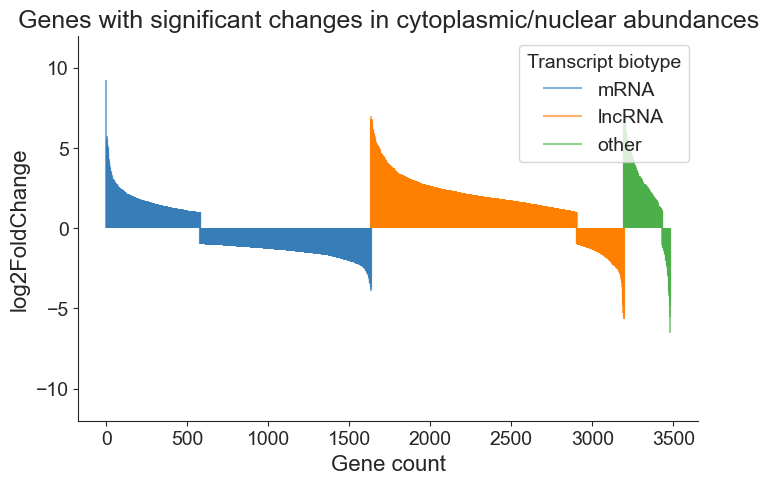

In [12]:
results_DESeq2_all_sig = results_DESeq2_all[results_DESeq2_all['localization_diff'] != 'No change']

df = results_DESeq2_all_sig.copy()
order = ['mRNA', 'lncRNA', 'other']
df['type'] = pd.Categorical(df['type'], categories=order, ordered=True)
df = df.sort_values(['type', 'log2FoldChange'], ascending=[True, False])
df['y'] = np.arange(len(df))

colors = [sns.color_palette('Set1')[1], sns.color_palette('Set1')[4], sns.color_palette('Set1')[2]]
plt.figure(figsize=(8, 5))
for i, cat in enumerate(order):
    sub = df[df['type'] == cat]
    plt.vlines(x=sub['y'], ymin=0, ymax=sub['log2FoldChange'], color=colors[i], alpha=0.6, label=cat, rasterized = True)
plt.legend(['mRNA', 'lncRNA', 'other'], title = 'Transcript biotype', fontsize = 14, title_fontsize = 14)
plt.ylim(-12, 12)
plt.ylabel('log2FoldChange', fontsize = 16)
plt.xlabel('Gene count', fontsize = 16)
plt.title('Genes with significant changes in cytoplasmic/nuclear abundances', fontsize = 18)
plt.tick_params(labelsize=14)
sns.despine()

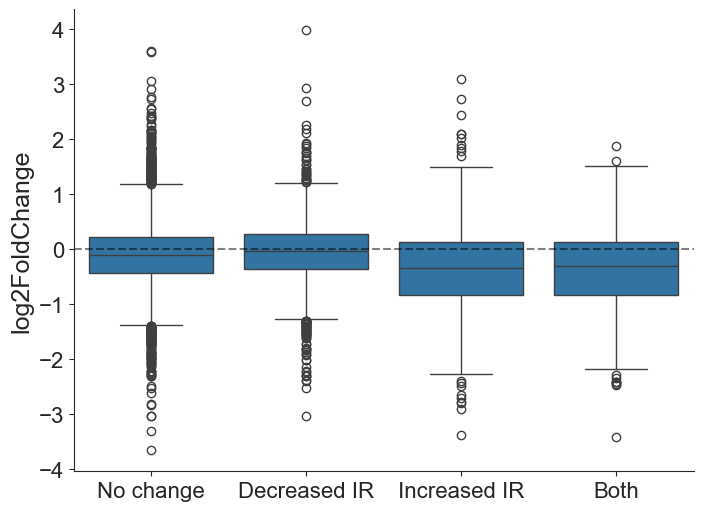

In [13]:
# Change of localization for genes with IR

nucleus_introns = pd.read_table('Fig3/IR_analysis_nuc.txt')
nucleus_introns.loc[nucleus_introns['sig'] == 'no', 'dir'] = 'not_significant'
genes_less_IR_nucleus = nucleus_introns[nucleus_introns['dir'] == 'less_IR_PABPN1']['gene_name'].drop_duplicates().tolist()
genes_more_IR_nucleus = nucleus_introns[nucleus_introns['dir'] == 'more_IR_PABPN1']['gene_name'].drop_duplicates().tolist()
genes_total_IR_nucleus = nucleus_introns['gene_name'].drop_duplicates().tolist()

results_DESeq2_all['IR_nucleus'] = 'Not detected'
results_DESeq2_all.loc[results_DESeq2_all['gene_name'].isin(genes_total_IR_nucleus), 'IR_nucleus'] = 'No change'
results_DESeq2_all.loc[results_DESeq2_all['gene_name'].isin(genes_less_IR_nucleus), 'IR_nucleus'] = 'Decreased IR'
results_DESeq2_all.loc[results_DESeq2_all['gene_name'].isin(genes_more_IR_nucleus), 'IR_nucleus'] = 'Increased IR'
results_DESeq2_all.loc[(results_DESeq2_all['gene_name'].isin(genes_less_IR_nucleus) & (results_DESeq2_all['gene_name'].isin(genes_more_IR_nucleus))), 'IR_nucleus'] = 'Both'

fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = results_DESeq2_all[results_DESeq2_all['IR_nucleus'] != 'Not detected'], x = 'IR_nucleus', y = 'log2FoldChange', order = ['No change', 'Decreased IR', 'Increased IR', 'Both'])
plt.axhline(y = 0, linestyle = '--', alpha = 0.5, color = 'black')
plt.ylabel("log2FoldChange", fontsize = 18)
plt.xlabel('')
plt.tick_params(labelsize = 16)
sns.despine()

In [14]:
# stat test
log2FC_notsig = results_DESeq2_all[results_DESeq2_all['IR_nucleus'] == 'No change']['log2FoldChange'].tolist()
log2FC_less_IR = results_DESeq2_all[results_DESeq2_all['IR_nucleus'] == 'Decreased IR']['log2FoldChange'].tolist()
log2FC_more_IR = results_DESeq2_all[results_DESeq2_all['IR_nucleus'] == 'Increased IR']['log2FoldChange'].tolist()
log2FC_both = results_DESeq2_all[results_DESeq2_all['IR_nucleus'] == 'Both']['log2FoldChange'].tolist()
pvalue_less_IR = stats.mannwhitneyu(x = log2FC_notsig, y = log2FC_less_IR)[1]
pvalue_more_IR = stats.mannwhitneyu(x = log2FC_notsig, y = log2FC_more_IR)[1]
pvalue_both = stats.mannwhitneyu(x = log2FC_notsig, y = log2FC_both)[1]

print("pvalue less IR = " + str(pvalue_less_IR))
print("pvalue more IR = " + str(pvalue_more_IR))
print("pvalue both = " + str(pvalue_both))

pvalue less IR = 2.9564707938894115e-06
pvalue more IR = 3.533204688659449e-22
pvalue both = 4.632313484135924e-16


In [15]:
results_DESeq2_cyto = pd.read_table('Fig4/resDF_cyto.txt')
results_DESeq2_cyto = results_DESeq2_cyto[results_DESeq2_cyto['gene_name'] != 'Y_RNA'] # remove Y_RNA : several genes with same name
results_DESeq2_cyto_count = results_DESeq2_cyto.groupby(by = ['diff_expression'])['gene_name'].count().reset_index()
results_DESeq2_cyto_count_type = results_DESeq2_cyto.groupby(by = ['diff_expression', 'type'])['gene_name'].count().reset_index() # count Geneid
genes_up_cyto = results_DESeq2_cyto[results_DESeq2_cyto['diff_expression'] == 'UP']['gene_name'].drop_duplicates().tolist() # get gene names in list to keep it the same as IR and APA
genes_down_cyto = results_DESeq2_cyto[results_DESeq2_cyto['diff_expression'] == 'DOWN']['gene_name'].drop_duplicates().tolist()
geneid_up_cyto = results_DESeq2_cyto[results_DESeq2_cyto['diff_expression'] == 'UP']['Geneid'].drop_duplicates().tolist()
geneid_down_cyto = results_DESeq2_cyto[results_DESeq2_cyto['diff_expression'] == 'DOWN']['Geneid'].drop_duplicates().tolist()
lncrna_up_cyto = results_DESeq2_cyto[(results_DESeq2_cyto['diff_expression'] == 'UP') & (results_DESeq2_cyto['type'] == 'lncrna')]['gene_name'].drop_duplicates().tolist()
lncrna_down_cyto = results_DESeq2_cyto[(results_DESeq2_cyto['diff_expression'] == 'DOWN') & (results_DESeq2_cyto['type'] == 'lncrna')]['gene_name'].drop_duplicates().tolist()

results_DESeq2_nucleus = pd.read_table('Fig4/resDF_nucleus.txt')
results_DESeq2_nucleus = results_DESeq2_nucleus[results_DESeq2_nucleus['gene_name'] != 'Y_RNA'] # remove Y_RNA : several genes with same name
results_DESeq2_nucleus_count = results_DESeq2_nucleus.groupby(by = ['diff_expression'])['gene_name'].count().reset_index()
results_DESeq2_nucleus_count_type = results_DESeq2_nucleus.groupby(by = ['diff_expression', 'type'])['gene_name'].count().reset_index()
genes_up_nucleus = results_DESeq2_nucleus[results_DESeq2_nucleus['diff_expression'] == 'UP']['gene_name'].drop_duplicates().tolist()
genes_down_nucleus = results_DESeq2_nucleus[results_DESeq2_nucleus['diff_expression'] == 'DOWN']['gene_name'].drop_duplicates().tolist()
geneid_up_nucleus = results_DESeq2_nucleus[results_DESeq2_nucleus['diff_expression'] == 'UP']['Geneid'].drop_duplicates().tolist()
geneid_down_nucleus = results_DESeq2_nucleus[results_DESeq2_nucleus['diff_expression'] == 'DOWN']['Geneid'].drop_duplicates().tolist()
lncrna_up_nucleus = results_DESeq2_nucleus[(results_DESeq2_nucleus['diff_expression'] == 'UP') & (results_DESeq2_nucleus['type'] == 'lncrna')]['gene_name'].drop_duplicates().tolist()
lncrna_down_nucleus = results_DESeq2_nucleus[(results_DESeq2_nucleus['diff_expression'] == 'DOWN') & (results_DESeq2_nucleus['type'] == 'lncrna')]['gene_name'].drop_duplicates().tolist()

results_DESeq2_nucleus.head()

,Geneid,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,gene_name,log10pval,diff_expression,type
16060,ENSG00000268471,12891.709716,3.528589,0.131000,26.935756,8.377219e-160,1.716660e-155,MIR4453HG,154.765316,UP,lncrna
7007,ENSG00000158286,10984.660657,-2.768531,0.105738,-26.182975,4.153270e-151,4.255441e-147,RNF207,146.371055,DOWN,mrna
19344,ENSG00000298649,4034.957170,3.030513,0.118724,25.525630,1.024045e-143,6.994909e-140,ENSG00000298649,139.155218,UP,lncrna
8110,ENSG00000167103,4952.381038,-2.864683,0.113575,-25.222772,2.253954e-140,1.154701e-136,PIP5KL1,135.937531,DOWN,mrna
18592,ENSG00000290792,25923.128205,2.648036,0.108690,24.363136,4.207629e-131,1.724455e-127,ENSG00000290792,126.763348,UP,lncrna


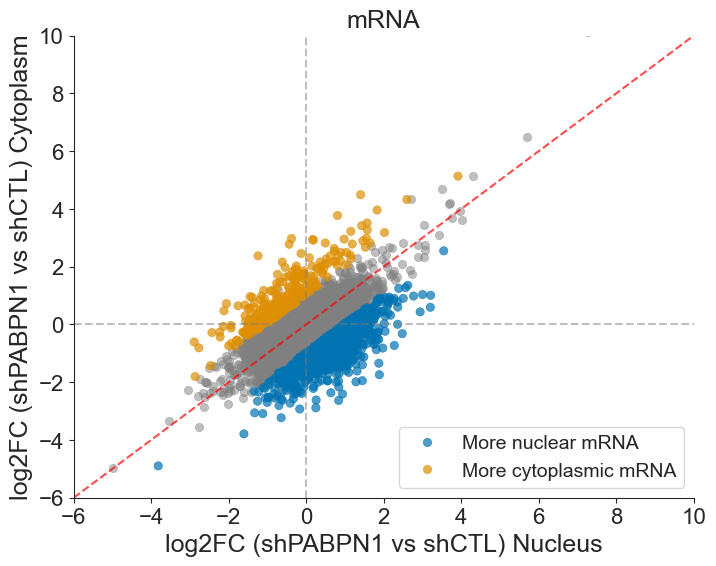

In [16]:
# scatterplots levels of expression in the nucleus and the cyto for more nuclear - more cytoplasmic genes

results_DESeq2_nucleus_cyto = results_DESeq2_nucleus.merge(results_DESeq2_cyto, on = ['Geneid', 'gene_name', 'type'])
results_DESeq2_nucleus_cyto['localization_diff'] = 'No change'
results_DESeq2_nucleus_cyto.loc[results_DESeq2_nucleus_cyto['Geneid'].isin(mrna_more_nuclear), 'localization_diff'] = 'More nuclear mRNA'
results_DESeq2_nucleus_cyto.loc[results_DESeq2_nucleus_cyto['Geneid'].isin(mrna_more_cytoplasmic), 'localization_diff'] = 'More cytoplasmic mRNA'
results_DESeq2_nucleus_cyto.loc[results_DESeq2_nucleus_cyto['Geneid'].isin(lncrna_more_nuclear), 'localization_diff'] = 'More nuclear lncRNA'
results_DESeq2_nucleus_cyto.loc[results_DESeq2_nucleus_cyto['Geneid'].isin(lncrna_more_cytoplasmic), 'localization_diff'] = 'More cytoplasmic lncRNA'

# mRNA
fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(data = results_DESeq2_nucleus_cyto[(results_DESeq2_nucleus_cyto['localization_diff'] == 'No change') & (results_DESeq2_nucleus_cyto['type'] == 'mrna')], x = 'log2FoldChange_x', y = 'log2FoldChange_y', color = 'grey', alpha = 0.5, edgecolor = None, rasterized = True)
sns.scatterplot(data = results_DESeq2_nucleus_cyto[(results_DESeq2_nucleus_cyto['localization_diff'] != 'No change') & (results_DESeq2_nucleus_cyto['type'] == 'mrna')],
                x = 'log2FoldChange_x', y = 'log2FoldChange_y', hue = 'localization_diff', alpha = 0.7, edgecolor = None, hue_order=['More nuclear mRNA', 'More cytoplasmic mRNA'], palette = 'colorblind', rasterized = True)
plt.xlim(-6,10)
plt.ylim(-6,10)
plt.axhline(y = 0, linestyle = '--', alpha = 0.5, color = 'grey')
plt.axvline(x = 0, linestyle = '--', alpha = 0.5, color = 'grey')
plt.plot((-6, 10), (-6, 10), color='red', linestyle='--', alpha=0.7)
plt.xlabel("log2FC (shPABPN1 vs shCTL) Nucleus", fontsize = 18)
plt.ylabel('log2FC (shPABPN1 vs shCTL) Cytoplasm', fontsize = 18)
plt.title('mRNA', fontsize = 18)
plt.tick_params(labelsize = 16)
plt.legend(fontsize = 14, title = '')
sns.despine()

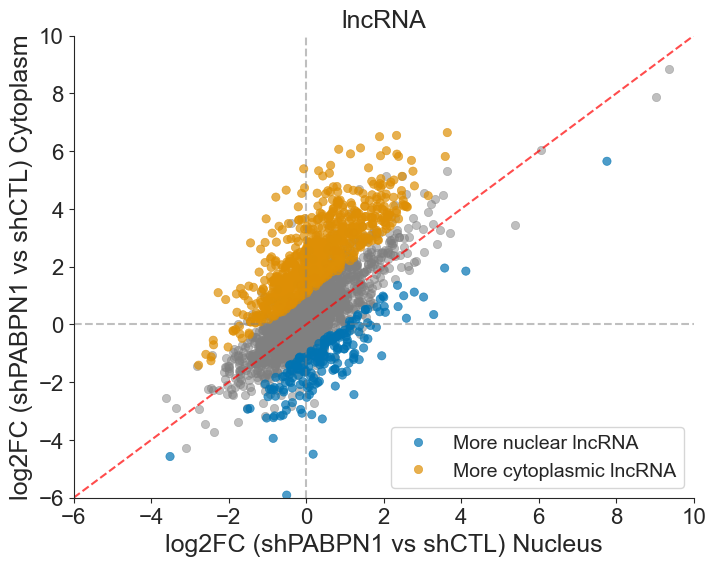

In [17]:
# lncRNA
fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(data = results_DESeq2_nucleus_cyto[(results_DESeq2_nucleus_cyto['localization_diff'] == 'No change') & (results_DESeq2_nucleus_cyto['type'] == 'lncrna')], x = 'log2FoldChange_x', y = 'log2FoldChange_y', color = 'grey', alpha = 0.5, edgecolor = None, rasterized = True)
sns.scatterplot(data = results_DESeq2_nucleus_cyto[(results_DESeq2_nucleus_cyto['localization_diff'] != 'No change') & (results_DESeq2_nucleus_cyto['type'] == 'lncrna')],
                x = 'log2FoldChange_x', y = 'log2FoldChange_y', hue = 'localization_diff', alpha = 0.7, edgecolor = None, hue_order=['More nuclear lncRNA', 'More cytoplasmic lncRNA'], palette = 'colorblind', rasterized = True)
plt.xlim(-6,10)
plt.ylim(-6,10)
plt.axhline(y = 0, linestyle = '--', alpha = 0.5, color = 'grey')
plt.axvline(x = 0, linestyle = '--', alpha = 0.5, color = 'grey')
plt.plot((-6, 10), (-6, 10), color='red', linestyle='--', alpha=0.7)
plt.xlabel("log2FC (shPABPN1 vs shCTL) Nucleus", fontsize = 18)
plt.ylabel('log2FC (shPABPN1 vs shCTL) Cytoplasm', fontsize = 18)
plt.title('lncRNA', fontsize = 18)
plt.tick_params(labelsize = 16)
plt.legend(fontsize = 14, title = '')
sns.despine()

In [18]:
global_reads_genes_polya = pd.read_table('Fig1/global_reads_genes_polya_without_gene_name.txt', index_col=[0])
global_reads_genes_polya = global_reads_genes_polya[global_reads_genes_polya['polya_length'] != 0] # remove reads without polyA

nucleus_reads_genes_polya = global_reads_genes_polya[global_reads_genes_polya['condition'].isin(['shCTL nucleus', 'shPABPN1 nucleus'])]
nucleus_reads_genes_polya.loc[nucleus_reads_genes_polya['ensembl_gene'].isin(lncrna_list), 'type'] = 'lncRNA'
nucleus_reads_genes_polya.loc[nucleus_reads_genes_polya['ensembl_gene'].isin(mrna_list), 'type'] = 'mRNA'

nucleus_reads_genes_polya.head()


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24164\1068859793.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nucleus_reads_genes_polya.loc[nucleus_reads_genes_polya['ensembl_gene'].isin(lncrna_list), 'type'] = 'lncRNA'


,reads,polya_length,ensembl_gene,condition,type
8817967,0179df5e-a1ba-47b6-90d0-7a752c162932,7,ENSG00000160789,shCTL nucleus,mRNA
8817970,010a9870-4767-4ddd-8e8b-f13c0d56dece,183,ENSG00000130635,shCTL nucleus,mRNA
8817972,015f8408-6016-4f61-9bf1-2128a1cf688c,205,ENSG00000176915,shCTL nucleus,mRNA
8817974,023450da-ef9c-4a62-b272-da6df968f174,192,ENSG00000117318,shCTL nucleus,mRNA
8817975,0241c19f-7bbe-4848-9402-528de27255b9,149,ENSG00000233276,shCTL nucleus,mRNA


In [19]:
nucleus_genes_median = nucleus_reads_genes_polya.groupby(by = ['ensembl_gene', 'type', 'condition'])['polya_length'].median().reset_index()
nucleus_genes_count = nucleus_reads_genes_polya.groupby(by = ['ensembl_gene', 'type', 'condition'])['reads'].count().reset_index()
nucleus_genes_median = nucleus_genes_median.merge(nucleus_genes_count, on = ['ensembl_gene', 'type', 'condition'])
nucleus_genes_median_cov = nucleus_genes_median[nucleus_genes_median['reads'] >= 20] # keep genes covered by at least 20 reads

nucleus_genes_median_cov.head()

,ensembl_gene,type,condition,polya_length,reads
0,ENSG00000000003,mRNA,shCTL nucleus,144.0,31
1,ENSG00000000003,mRNA,shPABPN1 nucleus,138.0,85
2,ENSG00000000419,mRNA,shCTL nucleus,216.0,557
3,ENSG00000000419,mRNA,shPABPN1 nucleus,160.0,844
4,ENSG00000000457,mRNA,shCTL nucleus,210.0,213


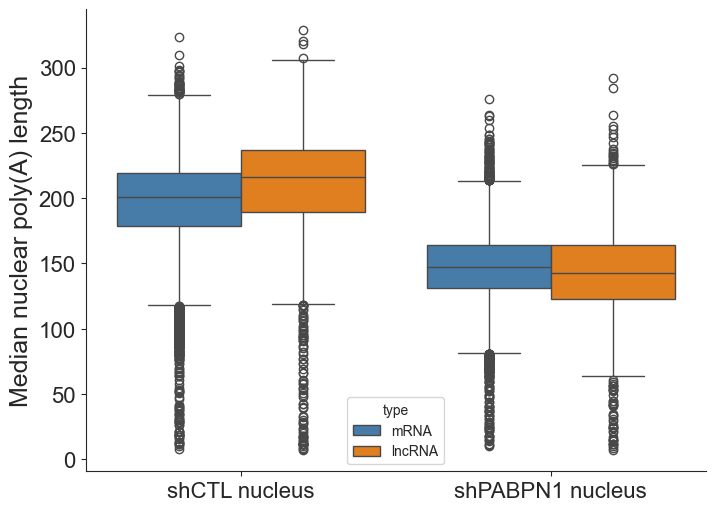

In [20]:
custom_palette = [sns.color_palette('Set1')[1], sns.color_palette('Set1')[4]]
fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = nucleus_genes_median_cov, hue = 'type', y = 'polya_length', x = 'condition', palette=custom_palette)
plt.ylabel("Median nuclear poly(A) length", fontsize = 18)
plt.xlabel('')
plt.tick_params(labelsize = 16)
sns.despine()

C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24164\187913719.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cyto_reads_genes_polya.loc[cyto_reads_genes_polya['ensembl_gene'].isin(lncrna_list), 'type'] = 'lncRNA'


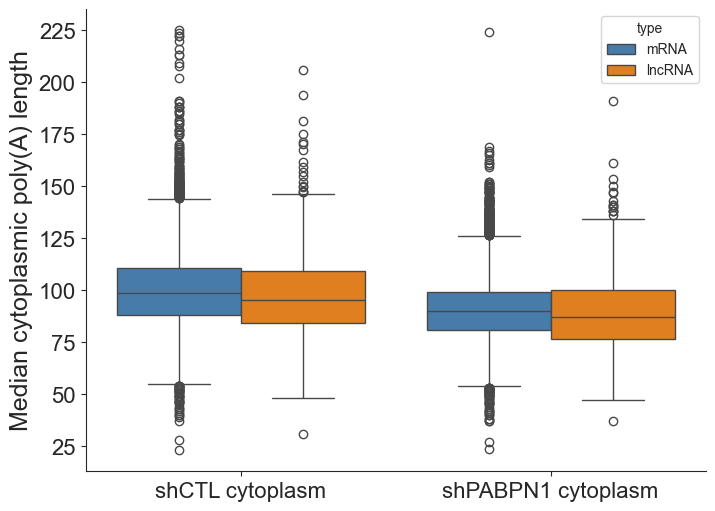

In [21]:
cyto_reads_genes_polya = global_reads_genes_polya[global_reads_genes_polya['condition'].isin(['shCTL cytoplasm', 'shPABPN1 cytoplasm'])]
cyto_reads_genes_polya.loc[cyto_reads_genes_polya['ensembl_gene'].isin(lncrna_list), 'type'] = 'lncRNA'
cyto_reads_genes_polya.loc[cyto_reads_genes_polya['ensembl_gene'].isin(mrna_list), 'type'] = 'mRNA'

cyto_genes_median = cyto_reads_genes_polya.groupby(by = ['ensembl_gene', 'type', 'condition'])['polya_length'].median().reset_index()
cyto_genes_count = cyto_reads_genes_polya.groupby(by = ['ensembl_gene', 'type', 'condition'])['reads'].count().reset_index()
cyto_genes_median = cyto_genes_median.merge(cyto_genes_count, on = ['ensembl_gene', 'type', 'condition'])
cyto_genes_median_cov = cyto_genes_median[cyto_genes_median['reads'] >= 20] # keep genes covered by at least 20 reads

custom_palette = [sns.color_palette('Set1')[1], sns.color_palette('Set1')[4]]
fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = cyto_genes_median_cov, hue = 'type', y = 'polya_length', x = 'condition', palette=custom_palette)
plt.ylabel("Median cytoplasmic poly(A) length", fontsize = 18)
plt.xlabel('')
plt.tick_params(labelsize = 16)
sns.despine()

C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24164\1815435033.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nucleus_genes_median_cov['localization_diff'] = 'No change'


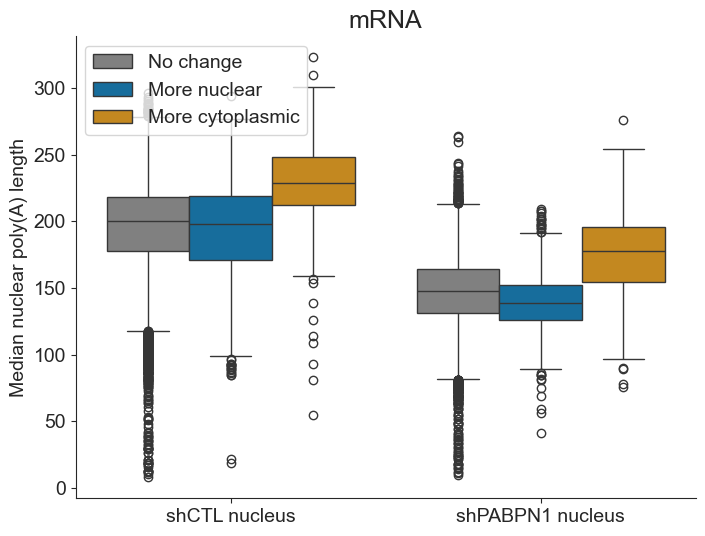

In [22]:
nucleus_genes_median_cov['localization_diff'] = 'No change'
nucleus_genes_median_cov.loc[nucleus_genes_median_cov['ensembl_gene'].isin(genes_more_nuclear), 'localization_diff'] = 'More nuclear'
nucleus_genes_median_cov.loc[nucleus_genes_median_cov['ensembl_gene'].isin(genes_more_cytoplasmic), 'localization_diff'] = 'More cytoplasmic'


custom_palette = ['grey', sns.color_palette('colorblind')[0], sns.color_palette('colorblind')[1]]
fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = nucleus_genes_median_cov[nucleus_genes_median_cov['type'] == 'mRNA'],
            hue = 'localization_diff', y = 'polya_length', x = 'condition', hue_order = ['No change', 'More nuclear', 'More cytoplasmic'], order=['shCTL nucleus', 'shPABPN1 nucleus'], palette = custom_palette)
plt.ylabel("Median nuclear poly(A) length", fontsize = 14)
plt.xlabel('')
plt.title('mRNA', fontsize = 18)
plt.tick_params(labelsize = 14)
sns.despine()
plt.legend(fontsize = 14, title = '', loc = 'upper left')

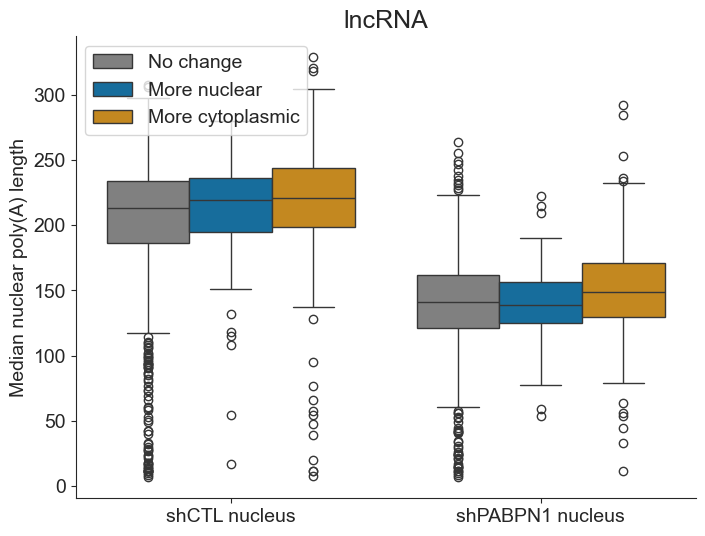

In [23]:
custom_palette = ['grey', sns.color_palette('colorblind')[0], sns.color_palette('colorblind')[1]]
fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = nucleus_genes_median_cov[nucleus_genes_median_cov['type'] == 'lncRNA'],
            hue = 'localization_diff', y = 'polya_length', x = 'condition', hue_order = ['No change', 'More nuclear', 'More cytoplasmic'], order=['shCTL nucleus', 'shPABPN1 nucleus'], palette = custom_palette)
plt.ylabel("Median nuclear poly(A) length", fontsize = 14)
plt.xlabel('')
plt.title('lncRNA', fontsize = 18)
plt.tick_params(labelsize = 14)
sns.despine()
plt.legend(fontsize = 14, title = '', loc = 'upper left')

In [24]:
# tsa seq data analysis

def get_prop_loc_diff(loc_diff, df, count) :
    df_loc = df[df['localization_diff'] == loc_diff]
    total = df_loc['gene_count'].sum()
    return((count/total) * 100)

def tsa_results_export(file, cell) :
    tsa_seq = pd.read_table(file).dropna()
    tsa_seq = tsa_seq[['gene_name', 'gene_id', 'gene_type', cell + '_SON_TSA_2.0', cell + '_SON_TSA_2.0.vigintiles']].rename(columns={cell + '_SON_TSA_2.0': 'tsa', cell + '_SON_TSA_2.0.vigintiles': 'vigintile'})
    tsa_seq['tsa'] = tsa_seq.apply(lambda row: float(str(row.tsa).replace(',', '.')), axis=1)
    tsa_seq['vigintile'] = tsa_seq.apply(lambda row: int(str(row.vigintile).split(' ')[1]), axis=1)
    tsa_seq['Geneid'] = tsa_seq.apply(lambda row: row.gene_id.split('.')[0], axis=1)
    results_DESeq2_all_tsa = results_DESeq2_all.merge(tsa_seq, on='Geneid')
    results_DESeq2_all_tsa_count = results_DESeq2_all_tsa.groupby(by=['type', 'localization_diff', 'vigintile'])['Geneid'].count().reset_index().sort_values('vigintile').rename(columns = {'Geneid' : 'gene_count'})
    results_DESeq2_all_tsa_count_mrna = results_DESeq2_all_tsa_count[results_DESeq2_all_tsa_count['type'] == 'mRNA']
    results_DESeq2_all_tsa_count_mrna['proportion'] = results_DESeq2_all_tsa_count_mrna.apply(lambda row: get_prop_loc_diff(row.localization_diff, results_DESeq2_all_tsa_count_mrna, row.gene_count), axis=1)
    results_DESeq2_all_tsa_count_mrna_piv = results_DESeq2_all_tsa_count_mrna.pivot_table(index='localization_diff',columns='vigintile',values='proportion').fillna(0)
    order = ['No change', 'More nuclear', 'More cytoplasmic']
    results_DESeq2_all_tsa_count_mrna_piv = results_DESeq2_all_tsa_count_mrna_piv.loc[order]

    # stat test
    other_nochange = results_DESeq2_all_tsa_count_mrna[(results_DESeq2_all_tsa_count_mrna['localization_diff'] == 'No change') & (results_DESeq2_all_tsa_count_mrna['vigintile'] != 20)]['gene_count'].sum()
    vig20_nochange = results_DESeq2_all_tsa_count_mrna[(results_DESeq2_all_tsa_count_mrna['localization_diff'] == 'No change') & (results_DESeq2_all_tsa_count_mrna['vigintile'] == 20)]['gene_count'].sum()
    other_more_cyto = results_DESeq2_all_tsa_count_mrna[(results_DESeq2_all_tsa_count_mrna['localization_diff'] == 'More cytoplasmic') & (results_DESeq2_all_tsa_count_mrna['vigintile'] != 20)]['gene_count'].sum()
    vig20_more_cyto = results_DESeq2_all_tsa_count_mrna[(results_DESeq2_all_tsa_count_mrna['localization_diff'] == 'More cytoplasmic') & (results_DESeq2_all_tsa_count_mrna['vigintile'] == 20)]['gene_count'].sum()
    other_more_nuc = results_DESeq2_all_tsa_count_mrna[(results_DESeq2_all_tsa_count_mrna['localization_diff'] == 'More nuclear') & (results_DESeq2_all_tsa_count_mrna['vigintile'] != 20)]['gene_count'].sum()
    vig20_more_nuc = results_DESeq2_all_tsa_count_mrna[(results_DESeq2_all_tsa_count_mrna['localization_diff'] == 'More nuclear') & (results_DESeq2_all_tsa_count_mrna['vigintile'] == 20)]['gene_count'].sum()
    pvalue_more_cyto = stats.fisher_exact([[other_nochange, vig20_nochange], [other_more_cyto, vig20_more_cyto]])[1]
    pvalue_more_nuc = stats.fisher_exact([[other_nochange, vig20_nochange], [other_more_nuc, vig20_more_nuc]])[1]
    return(results_DESeq2_all_tsa_count_mrna, results_DESeq2_all_tsa_count_mrna_piv, pvalue_more_cyto, pvalue_more_nuc)


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24164\3283910105.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results_DESeq2_all_tsa_count_mrna['proportion'] = results_DESeq2_all_tsa_count_mrna.apply(lambda row: get_prop_loc_diff(row.localization_diff, results_DESeq2_all_tsa_count_mrna, row.gene_count), axis=1)
C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24164\1617659144.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


pvalue_more_nuc_h1 = 1.6783339765192688e-21
pvalue_more_cyto_h1 = 1.069917755422154e-22


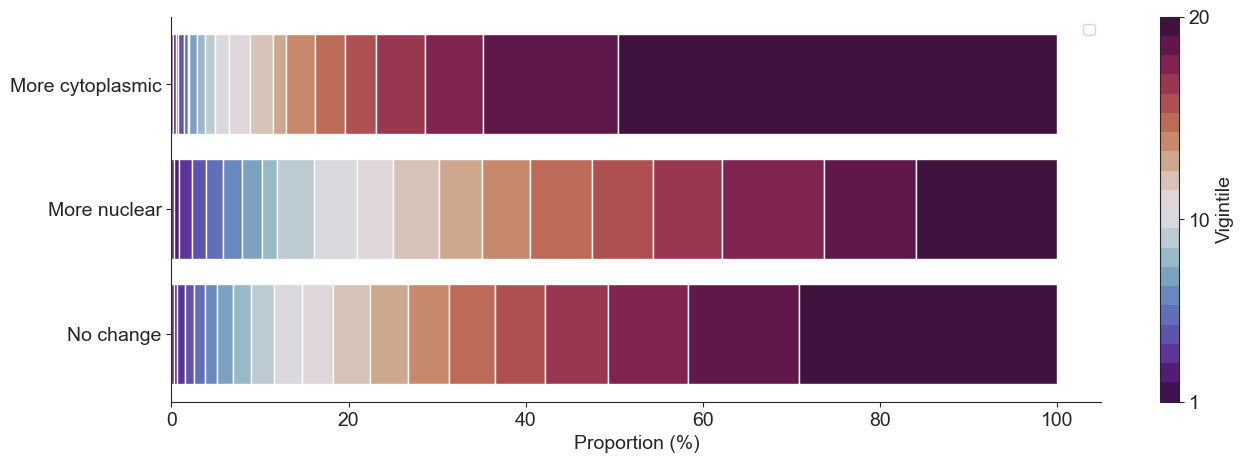

In [25]:
(results_DESeq2_all_tsa_count_mrna_h1, results_DESeq2_all_tsa_count_mrna_piv_h1, pvalue_more_cyto_h1, pvalue_more_nuc_h1) = tsa_results_export('C:/Users/bacs5867/Documents/PABPN1/tsa_seq/h1.txt', 'H1')

fig, ax = plt.subplots(figsize=(15,5))
left = np.zeros(len(results_DESeq2_all_tsa_count_mrna_piv_h1))
palette = sns.color_palette('twilight_shifted', n_colors=results_DESeq2_all_tsa_count_mrna_piv_h1.shape[1])
for i, col in enumerate(results_DESeq2_all_tsa_count_mrna_piv_h1.columns):
    ax.barh(results_DESeq2_all_tsa_count_mrna_piv_h1.index, results_DESeq2_all_tsa_count_mrna_piv_h1[col], left=left, color = palette[i])
    left += results_DESeq2_all_tsa_count_mrna_piv_h1[col].values
#ax.set_ylim(0, 1)
ax.tick_params(labelsize=14)
ax.set_xlabel('Proportion (%)', fontsize = 14)
ax.set_ylabel('')
sns.despine()
ax.legend()
# colorbar
cmap = mpl.colors.ListedColormap(palette)
norm = mpl.colors.Normalize(vmin=1, vmax=len(palette))
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_ticks([1, 10, len(palette)])
cbar.set_ticklabels(['1', '10', str(len(palette))])
cbar.ax.tick_params(labelsize=14)
cbar.set_label("Vigintile", fontsize = 14)

print('pvalue_more_nuc_h1 = ' + str(pvalue_more_nuc_h1))
print('pvalue_more_cyto_h1 = ' + str(pvalue_more_cyto_h1))

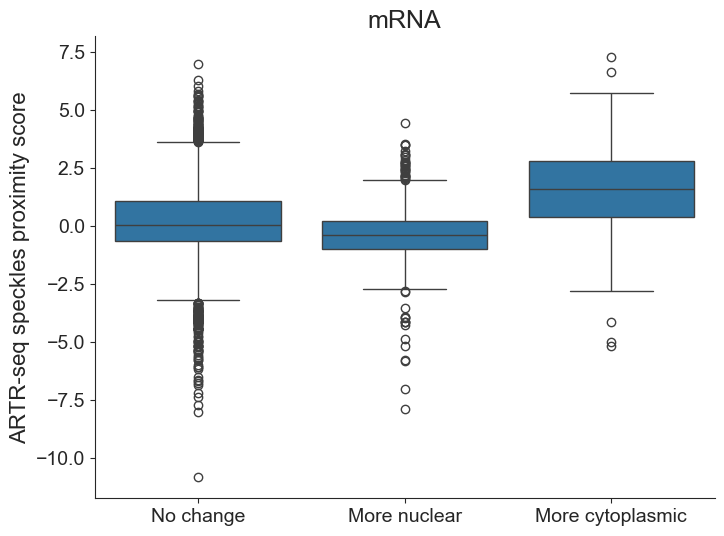

In [26]:
# ARTR seq data analysis

ARTR_Deseq2 = pd.read_table('C:/Users/bacs5867/Documents/PABPN1/ARTR_seq/DESeq2_SON_NT.txt')
ARTR_Deseq2['Geneid'] = ARTR_Deseq2.apply(lambda row: row.Geneid.split('.')[0], axis = 1)

results_DESeq2_all_artr = results_DESeq2_all.merge(ARTR_Deseq2, on = 'Geneid')
results_DESeq2_all_artr_mrna = results_DESeq2_all_artr[results_DESeq2_all_artr['type'] == 'mRNA']
results_DESeq2_all_artr_lncrna = results_DESeq2_all_artr[results_DESeq2_all_artr['type'] == 'lncRNA']

fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = results_DESeq2_all_artr_mrna, x = 'localization_diff', y = 'log2FoldChange_y', order = ['No change', 'More nuclear', 'More cytoplasmic'])
plt.ylabel('ARTR-seq speckles proximity score', fontsize = 16)
plt.xlabel('')
plt.title('mRNA', fontsize = 18)
plt.tick_params(labelsize = 14)
sns.despine()

In [27]:
# stat test
mrna_scores_no_change = results_DESeq2_all_artr_mrna[results_DESeq2_all_artr_mrna['localization_diff'] == 'No change']['log2FoldChange_y'].tolist()
mrna_scores_more_nuclear = results_DESeq2_all_artr_mrna[results_DESeq2_all_artr_mrna['localization_diff'] == 'More nuclear']['log2FoldChange_y'].tolist()
mrna_scores_more_cytoplasmic = results_DESeq2_all_artr_mrna[results_DESeq2_all_artr_mrna['localization_diff'] == 'More cytoplasmic']['log2FoldChange_y'].tolist()
pvalue_mrna_more_nuc = stats.mannwhitneyu(x = mrna_scores_no_change, y = mrna_scores_more_nuclear)[1]
pvalue_mrna_more_cyto = stats.mannwhitneyu(x = mrna_scores_no_change, y = mrna_scores_more_cytoplasmic)[1]

print('pvalue_mrna_more_nuc = ' + str(pvalue_mrna_more_nuc))
print('pvalue_mrna_more_cyto = ' + str(pvalue_mrna_more_cyto))


pvalue_mrna_more_nuc = 3.264305679491134e-39
pvalue_mrna_more_cyto = 2.974365211784357e-64


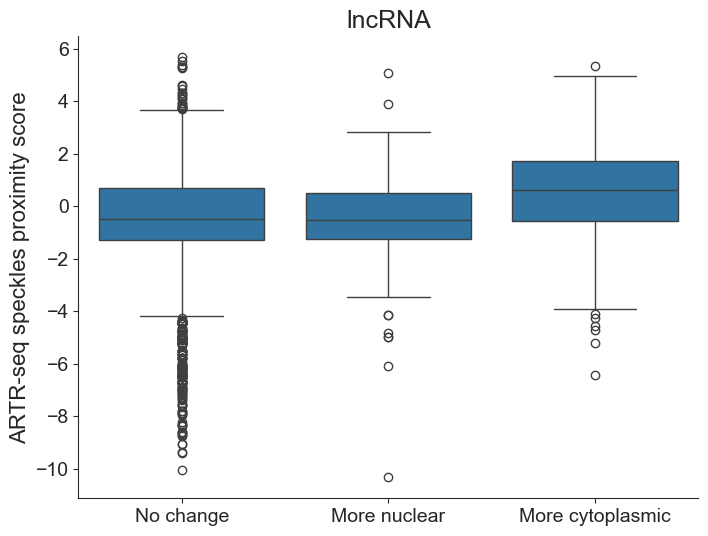

In [28]:
fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = results_DESeq2_all_artr_lncrna, x = 'localization_diff', y = 'log2FoldChange_y', order = ['No change', 'More nuclear', 'More cytoplasmic'])
plt.ylabel('ARTR-seq speckles proximity score', fontsize = 16)
plt.xlabel('')
plt.title('lncRNA', fontsize = 18)
#plt.xticks(ticks=[0,1,2,3], labels = ['No change', 'Decreased IR', 'Increased IR', 'Both'])
plt.tick_params(labelsize = 14)
sns.despine()

In [29]:
# stat test
lncrna_scores_no_change = results_DESeq2_all_artr_lncrna[results_DESeq2_all_artr_lncrna['localization_diff'] == 'No change']['log2FoldChange_y'].tolist()
lncrna_scores_more_nuclear = results_DESeq2_all_artr_lncrna[results_DESeq2_all_artr_lncrna['localization_diff'] == 'More nuclear']['log2FoldChange_y'].tolist()
lncrna_scores_more_cytoplasmic = results_DESeq2_all_artr_lncrna[results_DESeq2_all_artr_lncrna['localization_diff'] == 'More cytoplasmic']['log2FoldChange_y'].tolist()
pvalue_lncrna_more_nuc = stats.mannwhitneyu(x = lncrna_scores_no_change, y = lncrna_scores_more_nuclear)[1]
pvalue_lncrna_more_cyto = stats.mannwhitneyu(x = lncrna_scores_no_change, y = lncrna_scores_more_cytoplasmic)[1]

print('pvalue_lncrna_more_nuc = ' + str(pvalue_lncrna_more_nuc))
print('pvalue_lncrna_more_cyto = ' + str(pvalue_lncrna_more_cyto))

pvalue_lncrna_more_nuc = 0.888669288446017
pvalue_lncrna_more_cyto = 1.8188484158038342e-44
